# Epiphyte lysimeter analysis

Set everything in the **Settings** cell below, then **Run All**.

Sections:
1. Overview of all logged variables
2. Weight and mass loss (raw vs temperature-corrected)
3. Weight with fog periods (fog flag file)
4. Weight with FIESTA fog interception
5. Evapotranspiration (water balance)
6. Manual weighings check (optional)

A graph is only drawn when there is enough data for it (`MIN_POINTS`); otherwise the notebook prints why it was skipped.

In [66]:
# ======================================================================
#  SETTINGS: all inputs are here
# ======================================================================
from pathlib import Path

# ---- 1. Lysimeter log ----
DATA_PATH    = Path("lys1.csv")   # .csv or .xlsx (an .xlsx is also saved as .csv)
SHEET        = 0                   # only for .xlsx: sheet name or index
START        = None                # analysis window, e.g. "2026-10-15 13:00"; None = from the first row
END          = None                # e.g. "2026-10-16 15:00"; None = to the last row
DROP_FLAGGED = True                # drop rows where the load-cell amplifier failed (status contains "HX_")

# ---- 2. Calibration and temperature correction ----
#   weight_g = (ADC − ADC0 − ALPHA·ΔT) × SLOPE / (1 + BETA·ΔT),   ΔT = T − T_REF
ADC0        = 30882                # ADC reading of the empty lysimeter (tare)
SLOPE       = 0.009943             # grams per ADC count
T_REF       = 20.1                 # temperature (°C) at which ADC0 was measured
ALPHA       = -188.1                # zero drift (counts/°C), overnight regression
BETA        = 0.002219           # span drift (fraction/°C) from the calibration sessions; 0 = zero correction only
CAL_T_RANGE = (17.0, 21.0)         # temperatures of the calibration sessions (warning if far outside)


# ---- 3. Watering experiment / water balance ----
PRE_START, PRE_END = "2026-10-15 14:30", "2026-10-15 15:17"    # stable period BEFORE watering (base weight); None = skip the watering check
ET_START,  ET_END  = "2026-10-15 17:45:11", None    # drying period AFTER drainage stopped; None = whole window
WATER_ADDED_ML     = 300           # water added at watering (ml)
TIP_ML             = 6.28          # drainage per bucket tip (ml)
AREA_CM2           = 150          # area (cm²) to also report ET in mm; None = ml only
DAY_HOURS          = (6, 18)       # day = 06:00–18:00 for the day/night ET split

# ---- 4. Fog flag file ----
FOG_PATH     = Path("fog_data.csv")      # None = no fog flag file
FOG_FLAG_COL = "FOG_TEMPEST_RH"       # 1 = fog, 0 = no fog; None = first column starting with "FOG"
FOG_SHIFT_H  = 0                         # hours to add if the fog logger runs on another clock

# ---- 5. FIESTA fog interception (weather station file) ----
MET_PATH       = Path("fog_AF_15min.csv")  # None = skip
FIESTA_COL     = "fiesta_fog_mm"           # modelled fog interception per interval (mm)
MET_FLAG_COL   = "fog_flag"                # used for fog periods only if there is no fog flag file
RAIN_COL       = "rain_mm"                 # None = don't show rain
PLANT_AREA_CM2 = 150.0                     # epiphyte area facing the fog (cm²)
EFFICIENCY     = 1.0                       # plant capture relative to the model (1 = same)
LOCAL_TZ       = "America/Guatemala"       # time zone of the lysimeter clock

# ---- 6. Manual weighings (optional) ----
MANUAL            = [("12:15", 200), ("14:25", 200), ("16:30", 190), ("19:50", 175), ("21:00", 180),
                     ("07:00", 200), ("8:31", 185)]             # e.g. [("15:30", 70), ("18:00", 125)]; [] = skip
MANUAL_START_DATE = None           # date of the first weighing; None = first day of the window
MANUAL_RES_G      = 5              # ± resolution of the manual scale (g)

# ---- 7. Output and uncertainty ----
MIN_POINTS  = 8                    # minimum data points for a graph to be drawn
SAVE_PNG    = False                 # save every graph next to the data file
N_AVG       = 3                    # readings averaged at each end of a period
TIP_CAL_ERR = 0.03                 # relative uncertainty of TIP_ML
TEMP_RESID  = 0.9                  # g/°C assumed left after temperature correction

# ---- 8. Report: pass criteria ----
CLOSURE_TOL       = 0.05           # water balance: ΔS + D must be within ±5 % of WATER_ADDED_ML
TRACK_TOL_G       = None           # tracking: allowed |logger − manual| (g) after removing the offset; None = report the value reached (= ±[X])
CONDENSATION_SEEN = None           # visual check on opening the enclosure: True / False; None = not recorded
RH_SATURATED      = 99             # RH (%) counted as saturated (no evaporation possible, condensation risk)

## Setup (no settings below this point)

In [67]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
%matplotlib inline
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

COLUMNS = ["boot_session", "elapsed_sec", "timestamp", "avg_temperature_C",
           "avg_humidity_pct", "avg_raw_adc", "avg_weight_g", "total_tips", "status"]


def load(path, sheet=0):
    path = Path(path)
    if path.suffix.lower() in (".xlsx", ".xlsm", ".xls"):
        d = pd.read_excel(path, sheet_name=sheet)
    else:
        d = pd.read_csv(path, sep=None, engine="python")
    d.columns = [str(c).strip() for c in d.columns]
    missing = [c for c in COLUMNS if c not in d.columns]
    if missing:
        raise ValueError(f"Missing columns: {missing}. Found: {list(d.columns)}")
    d = d[COLUMNS].copy()
    d["timestamp"] = pd.to_datetime(d["timestamp"], errors="coerce")
    for c in COLUMNS[3:8] + ["elapsed_sec"]:
        d[c] = pd.to_numeric(d[c], errors="coerce")
    d["status"] = d["status"].astype(str).str.strip()
    return d.dropna(subset=["timestamp"]).sort_values("timestamp").reset_index(drop=True)


def select_window(d, start=None, end=None, col="timestamp"):
    m = d[col].notna()
    if start is not None: m &= d[col] >= pd.Timestamp(start)
    if end is not None:   m &= d[col] <= pd.Timestamp(end)
    return d[m].copy()


def weight_tc(adc, temp_c):
    dT = np.asarray(temp_c, float) - T_REF
    return (np.asarray(adc, float) - ADC0 - ALPHA * dT) * SLOPE / (1 + BETA * dT)


def to_local_naive(s):
    """Parse timestamps; if they carry an offset (e.g. -06:00 or Z), convert to LOCAL_TZ and drop it."""
    if s.astype(str).str.contains(r"[+-]\d\d:\d\d$|Z$", regex=True).any():
        return pd.to_datetime(s, errors="coerce", utc=True).dt.tz_convert(LOCAL_TZ).dt.tz_localize(None)
    return pd.to_datetime(s, errors="coerce")


def time_col(d):
    for c in d.columns:
        if c.lower() in ("timestamp", "time", "datetime", "date_time"):
            return c
    return d.columns[0]


def file_ok(path, what):
    if path is None:
        print(f"⏭ {what}: no file set")
        return False
    if not Path(path).exists():
        print(f"⏭ {what}: file not found ({path})")
        return False
    return True


def enough(n, what, need=None):
    need = MIN_POINTS if need is None else need
    if n < need:
        print(f"⏭ Skipped '{what}': only {n} data point(s), need at least {need}")
        return False
    return True


def periods_from_flag(ts, flag):
    """Turn a 0/1 flag time series into a list of (start, end) periods."""
    f = pd.DataFrame({"t": ts, "on": flag}).dropna(subset=["t"]).sort_values("t").reset_index(drop=True)
    if f.empty or not f["on"].any():
        return []
    step = f["t"].diff().median()
    block = (f["on"] != f["on"].shift()).cumsum()
    return [(g["t"].iloc[0], g["t"].iloc[-1] + step) for _, g in f[f["on"]].groupby(block[f["on"]])]


def clip_periods(periods, a, b):
    return [(max(p, a), min(q, b)) for p, q in periods if q > a and p < b]


def shade(ax, periods, color="lightsteelblue", label="fog"):
    for j, (p, q) in enumerate(periods):
        ax.axvspan(p, q, color=color, alpha=0.35, lw=0, label=label if j == 0 else None)


def time_axis(ax):
    loc = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(loc)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))


def finish(fig, name):
    if SAVE_PNG:
        out = DATA_PATH.with_name(f"{DATA_PATH.stem}_{name}.png")
        fig.savefig(out, dpi=150, bbox_inches="tight")
        print(f"Saved {out}")
    plt.show()


def add_temperature(ax, d):
    tw = ax.twinx()
    tw.plot(d["timestamp"], d["avg_temperature_C"], color="tab:red", lw=0.8, alpha=0.5, label="temperature")
    tw.set_ylabel("Temperature (°C)", color="tab:red")
    tw.grid(False)
    return tw


def legend_all(fig_or_ax, axes, **kw):
    h, l = [], []
    for a_ in axes:
        hh, ll = a_.get_legend_handles_labels(); h += hh; l += ll
    fig_or_ax.legend(h, l, fontsize=8, frameon=False, **kw)

## Load and prepare data

In [68]:
df = load(DATA_PATH, SHEET)
print(f"Loaded {DATA_PATH}: {len(df)} rows, {df['timestamp'].min()} → {df['timestamp'].max()}")
if DATA_PATH.suffix.lower() != ".csv":
    df.to_csv(DATA_PATH.with_suffix(".csv"), index=False)
    print(f"Saved CSV copy: {DATA_PATH.with_suffix('.csv')}")

if DROP_FLAGGED:
    bad = df["status"].str.contains("HX_") | df["avg_raw_adc"].isna()
    if bad.any():
        print(f"Dropped {bad.sum()} row(s) with a failed load-cell reading (HX_ flag or no ADC value)")
    df = df[~bad].copy()

dw = select_window(df, START, END)
if dw.empty:
    raise ValueError(f"No rows between {START} and {END}. Data covers {df['timestamp'].min()} → {df['timestamp'].max()}")
t0, t1 = dw["timestamp"].min(), dw["timestamp"].max()
hours_total = (t1 - t0).total_seconds() / 3600

dw["weight_raw_g"] = (dw["avg_raw_adc"] - ADC0) * SLOPE
dw["weight_g"]     = weight_tc(dw["avg_raw_adc"], dw["avg_temperature_C"])     # temperature-corrected
dw["tips_inc"]     = dw.groupby("boot_session")["total_tips"].diff().fillna(0).clip(lower=0)
dw["drain_ml"]     = dw["tips_inc"].cumsum() * TIP_ML

print(f"Window: {t0} → {t1} ({hours_total:.1f} h, {len(dw)} rows, {dw['boot_session'].nunique()} boot session(s))")
print(f"Temperature correction: zero {ALPHA * SLOPE:+.2f} g/°C, span {100 * BETA:+.3f} %/°C, reference {T_REF} °C")
if dw["avg_temperature_C"].notna().any():
    lo, hi = dw["avg_temperature_C"].min(), dw["avg_temperature_C"].max()
    if lo < CAL_T_RANGE[0] - 2 or hi > CAL_T_RANGE[1] + 2:
        print(f"⚠ Temperatures {lo:.1f}–{hi:.1f} °C are more than 2 °C outside the calibration range "
              f"{CAL_T_RANGE[0]}–{CAL_T_RANGE[1]} °C: the span correction is extrapolated.")
if dw["boot_session"].nunique() > 1:
    print("⚠ The window spans a reboot: check that the weight doesn't jump at the reboot.")

summary = pd.Series({
    "weight start, corrected (g)": dw["weight_g"].iloc[0],
    "weight end, corrected (g)": dw["weight_g"].iloc[-1],
    "weight change, corrected (g)": dw["weight_g"].iloc[-1] - dw["weight_g"].iloc[0],
    "weight change, raw (g)": dw["weight_raw_g"].iloc[-1] - dw["weight_raw_g"].iloc[0],
    "drainage (ml)": dw["drain_ml"].iloc[-1],
    "mean temperature (°C)": dw["avg_temperature_C"].mean(),
    "temperature range (°C)": dw["avg_temperature_C"].max() - dw["avg_temperature_C"].min(),
    "mean humidity (%)": dw["avg_humidity_pct"].mean(),
})
display(summary.round(2).to_frame("value"))

Loaded lys1.csv: 99 rows, 2026-10-16 08:19:57 → 2026-10-17 08:52:18
Dropped 30 row(s) with a failed load-cell reading (HX_ flag or no ADC value)
Window: 2026-10-16 08:19:57 → 2026-10-17 08:52:18 (24.5 h, 69 rows, 1 boot session(s))
Temperature correction: zero -1.87 g/°C, span +0.222 %/°C, reference 20.1 °C
⚠ Temperatures 17.7–23.3 °C are more than 2 °C outside the calibration range 17.0–21.0 °C: the span correction is extrapolated.


,value
"weight start, corrected (g)",0.99
"weight end, corrected (g)",182.91
"weight change, corrected (g)",181.91
"weight change, raw (g)",183.47
drainage (ml),238.64
mean temperature (°C),20.38
temperature range (°C),5.60
mean humidity (%),94.51


In [69]:
# ---- Fog flag and weather-station files ----
fog_periods_all, met, mw, met_step = [], None, None, None

if file_ok(FOG_PATH, "Fog flag"):
    fog = pd.read_csv(FOG_PATH, sep=None, engine="python")
    fog.columns = [c.strip() for c in fog.columns]
    fcol = FOG_FLAG_COL if FOG_FLAG_COL in fog.columns else \
        next((c for c in fog.columns if c.upper().startswith("FOG")), None)
    if fcol is None:
        print(f"⏭ Fog flag: no column '{FOG_FLAG_COL}' or starting with 'FOG' in {FOG_PATH}")
    else:
        ts = to_local_naive(fog[time_col(fog)]) + pd.Timedelta(hours=FOG_SHIFT_H)
        fog_periods_all = periods_from_flag(ts, pd.to_numeric(fog[fcol], errors="coerce").fillna(0) >= 0.5)
        print(f"Fog flag: column '{fcol}', {len(fog_periods_all)} fog period(s) in the file")

if file_ok(MET_PATH, "Weather station / FIESTA"):
    met = pd.read_csv(MET_PATH, sep=None, engine="python")
    met.columns = [c.strip() for c in met.columns]
    met["Timestamp"] = to_local_naive(met[time_col(met)])
    met = met.dropna(subset=["Timestamp"]).sort_values("Timestamp").reset_index(drop=True)
    for c in (FIESTA_COL, MET_FLAG_COL, RAIN_COL):
        if c and c in met.columns:
            met[c] = pd.to_numeric(met[c], errors="coerce").fillna(0)
    met_step = met["Timestamp"].diff().median()
    mw = met[(met["Timestamp"] >= t0 - met_step) & (met["Timestamp"] <= t1)].copy()
    print(f"Weather station: {len(mw)} row(s) in the window (interval {met_step})")
    if not fog_periods_all and MET_FLAG_COL in met.columns:
        fog_periods_all = periods_from_flag(met["Timestamp"], met[MET_FLAG_COL] >= 0.5)
        print(f"Fog periods taken from '{MET_FLAG_COL}' in the weather-station file")

fog_periods = clip_periods(fog_periods_all, t0, t1)
fog_hours = sum((q - p).total_seconds() for p, q in fog_periods) / 3600
print(f"Fog in the window: {len(fog_periods)} period(s), {fog_hours:.1f} h")

Fog flag: column 'FOG_TEMPEST_RH', 55 fog period(s) in the file
Weather station: 31 row(s) in the window (interval 0 days 00:15:00)
Fog in the window: 9 period(s), 6.6 h


## 1. Overview of all logged variables

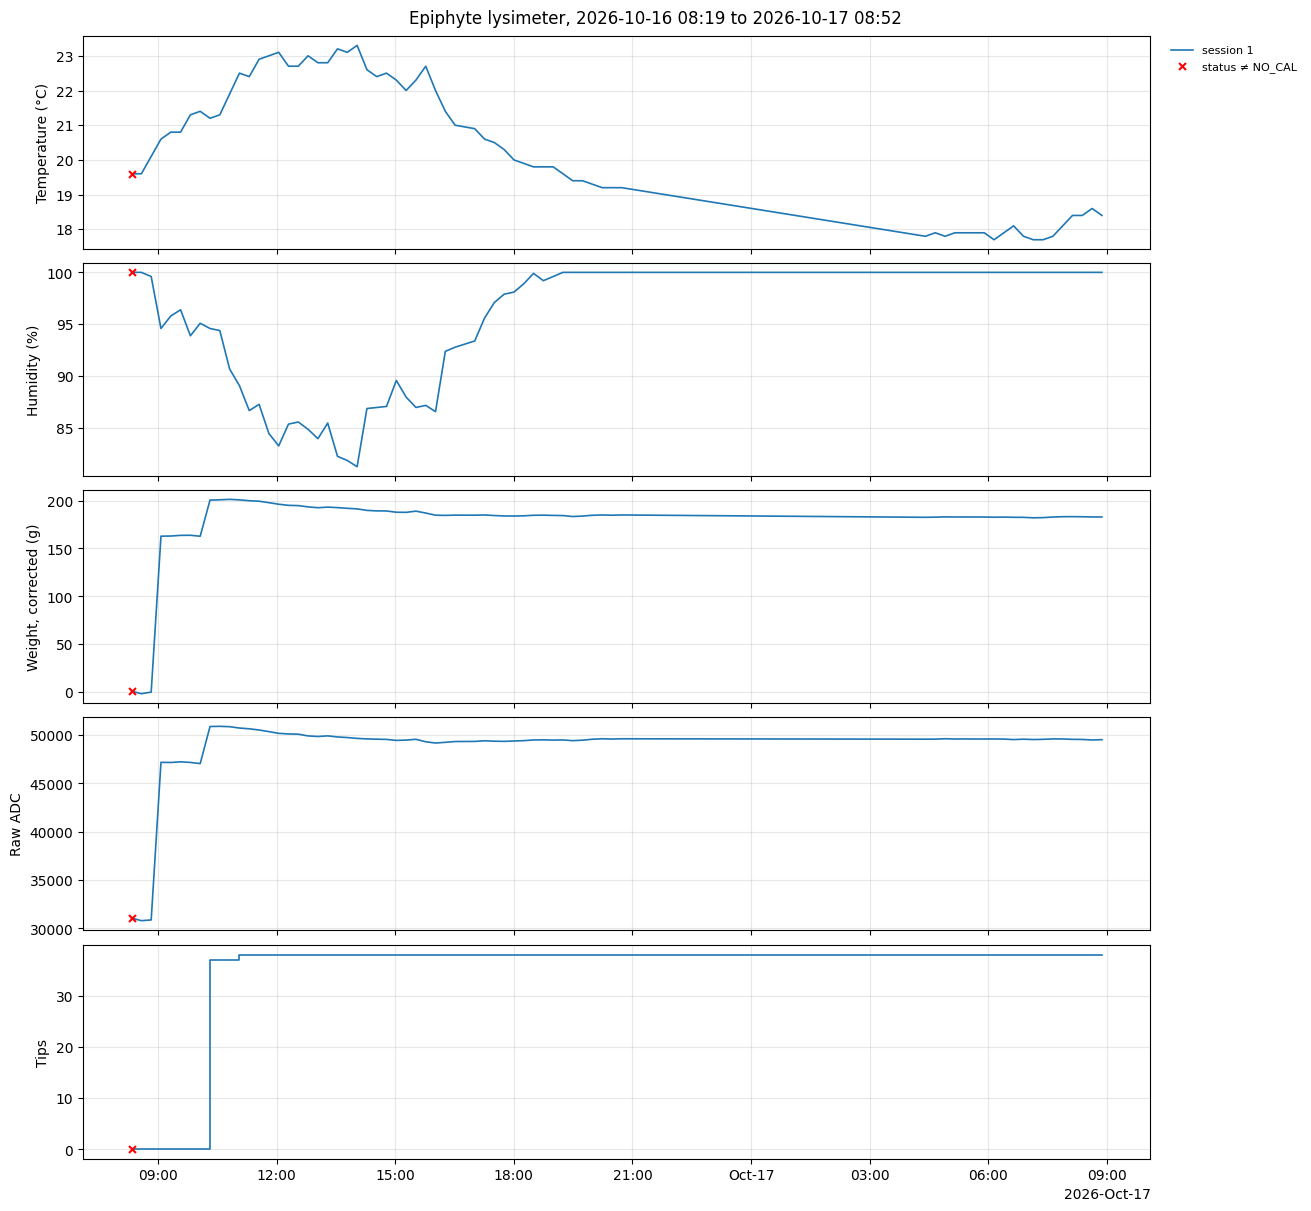

In [70]:
PANELS = [("avg_temperature_C", "Temperature (°C)", "line"),
          ("avg_humidity_pct", "Humidity (%)", "line"),
          ("weight_g", "Weight, corrected (g)", "line"),
          ("avg_raw_adc", "Raw ADC", "line"),
          ("total_tips", "Tips", "step")]
panels = [p for p in PANELS if dw[p[0]].notna().sum() >= MIN_POINTS]

if enough(len(dw), "overview") and panels:
    normal = dw["status"].mode().iloc[0]
    flagged = dw[dw["status"] != normal]
    fig, axes = plt.subplots(len(panels), 1, figsize=(13, 2.4 * len(panels)), sharex=True,
                             constrained_layout=True, squeeze=False)
    for ax, (col, label, kind) in zip(axes[:, 0], panels):
        for i, (s, d) in enumerate(dw.groupby("boot_session", sort=False)):
            c = plt.get_cmap("tab10")(i % 10)
            (ax.step(d["timestamp"], d[col], where="post", color=c, lw=1.2, label=f"session {s}")
             if kind == "step" else ax.plot(d["timestamp"], d[col], color=c, lw=1.2, label=f"session {s}"))
        if not flagged.empty:
            ax.scatter(flagged["timestamp"], flagged[col], marker="x", color="red", s=25, zorder=5,
                       label=f"status ≠ {normal}")
        ax.set_ylabel(label)
    axes[0, 0].legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8, frameon=False)
    time_axis(axes[-1, 0])
    fig.suptitle(f"Epiphyte lysimeter, {t0:%Y-%m-%d %H:%M} to {t1:%Y-%m-%d %H:%M}")
    finish(fig, "overview")

## 2. Weight and mass loss

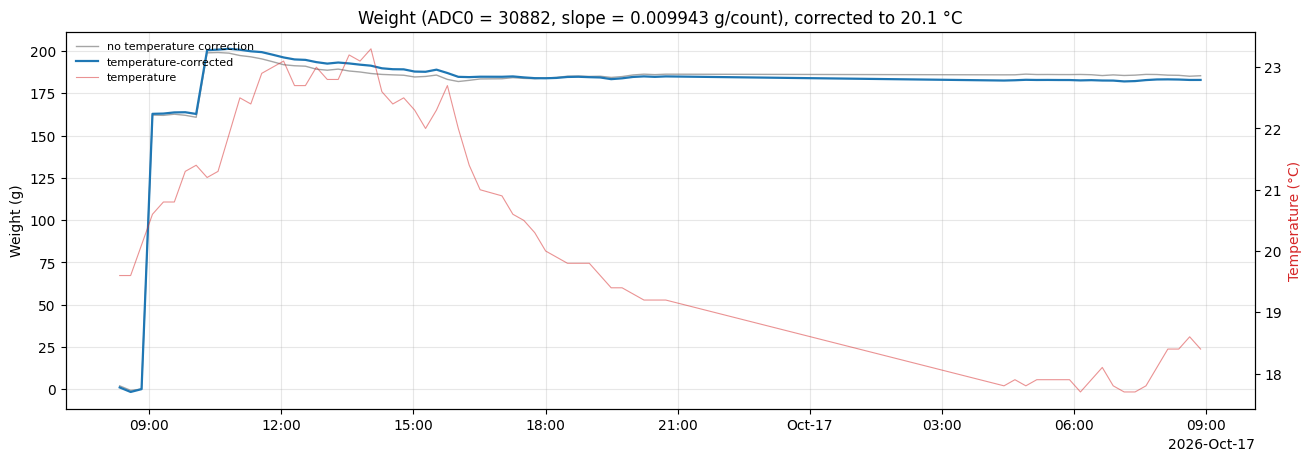

In [71]:
# ---- Weight: raw vs temperature-corrected, with temperature ----
if enough(dw["weight_g"].notna().sum(), "weight with temperature correction"):
    fig, ax = plt.subplots(figsize=(13, 4.5), constrained_layout=True)
    for i, (s, g) in enumerate(dw.groupby("boot_session", sort=False)):
        ax.plot(g["timestamp"], g["weight_raw_g"], color="tab:grey", lw=1, alpha=0.7,
                label="no temperature correction" if i == 0 else None)
        ax.plot(g["timestamp"], g["weight_g"], color="tab:blue", lw=1.6,
                label="temperature-corrected" if i == 0 else None)
    ax.set_ylabel("Weight (g)")
    tw = add_temperature(ax, dw)
    legend_all(ax, [ax, tw], loc="upper left")
    ax.set_title(f"Weight (ADC0 = {ADC0}, slope = {SLOPE} g/count), corrected to {T_REF} °C")
    time_axis(ax)
    finish(fig, "weight_temperature")

No base period set: water added is not included (WATER_ADDED_ML ignored).


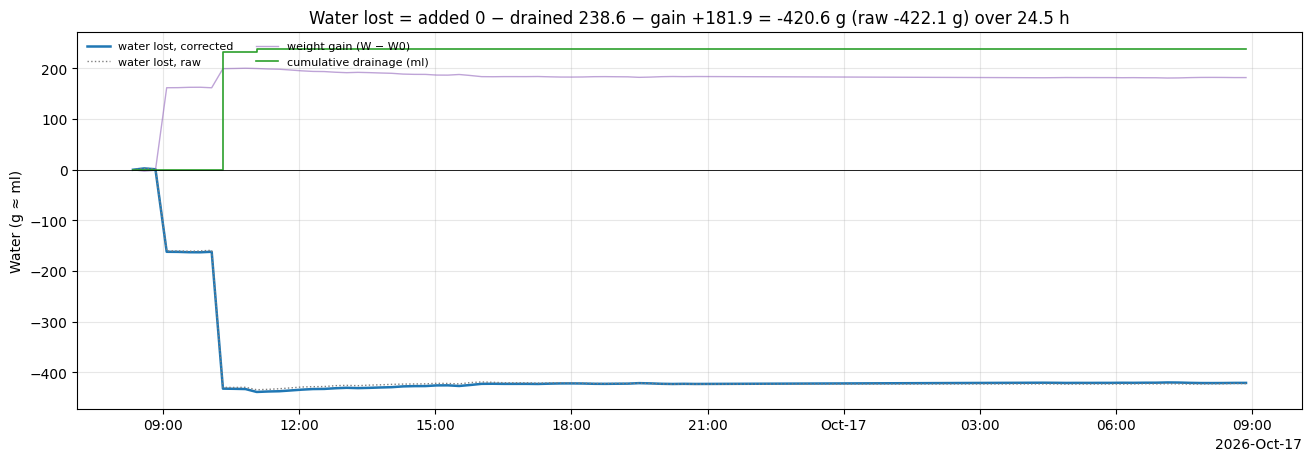

In [72]:
# ---- Mass loss since the start of the window (water balance) ----
#   loss(t) = water added(t) − drainage(t) − weight gain(t),   weight gain = W(t) − W0
#   W0 = mean weight in the base period before watering (PRE_START–PRE_END), else the first reading
if enough(dw["weight_g"].notna().sum(), "mass loss"):
    if PRE_START is not None and PRE_END is not None and len(select_window(dw, PRE_START, PRE_END)):
        pre_ = select_window(dw, PRE_START, PRE_END)
        W0c, W0r = pre_["weight_g"].mean(), pre_["weight_raw_g"].mean()
        t_water = dw.loc[dw["timestamp"] > pd.Timestamp(PRE_END), "timestamp"].min()   # watering just after the base period
    else:
        W0c, W0r = dw["weight_g"].iloc[0], dw["weight_raw_g"].iloc[0]
        t_water = None
        print("No base period set: water added is not included (WATER_ADDED_ML ignored).")

    added = np.where(dw["timestamp"] >= t_water, WATER_ADDED_ML, 0.0) if t_water is not None else np.zeros(len(dw))
    dw["water_added_ml"]  = added
    dw["weight_gain_g"]   = dw["weight_g"] - W0c
    dw["mass_loss_g"]     = dw["water_added_ml"] - dw["drain_ml"] - dw["weight_gain_g"]
    dw["mass_loss_raw_g"] = dw["water_added_ml"] - dw["drain_ml"] - (dw["weight_raw_g"] - W0r)

    fig, ax = plt.subplots(figsize=(13, 4.5), constrained_layout=True)
    ax.plot(dw["timestamp"], dw["mass_loss_g"], color="tab:blue", lw=1.8, label="water lost, corrected")
    ax.plot(dw["timestamp"], dw["mass_loss_raw_g"], color="tab:grey", lw=1, ls=":", label="water lost, raw")
    ax.plot(dw["timestamp"], dw["weight_gain_g"], color="tab:purple", lw=1, alpha=0.6, label="weight gain (W − W0)")
    if t_water is not None:
        ax.step(dw["timestamp"], dw["water_added_ml"], where="post", color="tab:cyan", lw=1.2, label="water added (ml)")
    if dw["drain_ml"].iloc[-1] > 0:
        ax.step(dw["timestamp"], dw["drain_ml"], where="post", color="tab:green", lw=1.2, label="cumulative drainage (ml)")
    ax.axhline(0, color="k", lw=0.6)
    ax.set_ylabel("Water (g ≈ ml)")
    ax.set_title(f"Water lost = added {dw['water_added_ml'].iloc[-1]:.0f} − drained {dw['drain_ml'].iloc[-1]:.1f} "
                 f"− gain {dw['weight_gain_g'].iloc[-1]:+.1f} = {dw['mass_loss_g'].iloc[-1]:.1f} g "
                 f"(raw {dw['mass_loss_raw_g'].iloc[-1]:.1f} g) over {hours_total:.1f} h")
    ax.legend(loc="upper left", fontsize=8, frameon=False, ncol=2)
    time_axis(ax)
    finish(fig, "mass_loss")

## 3. Weight with fog periods (fog flag)

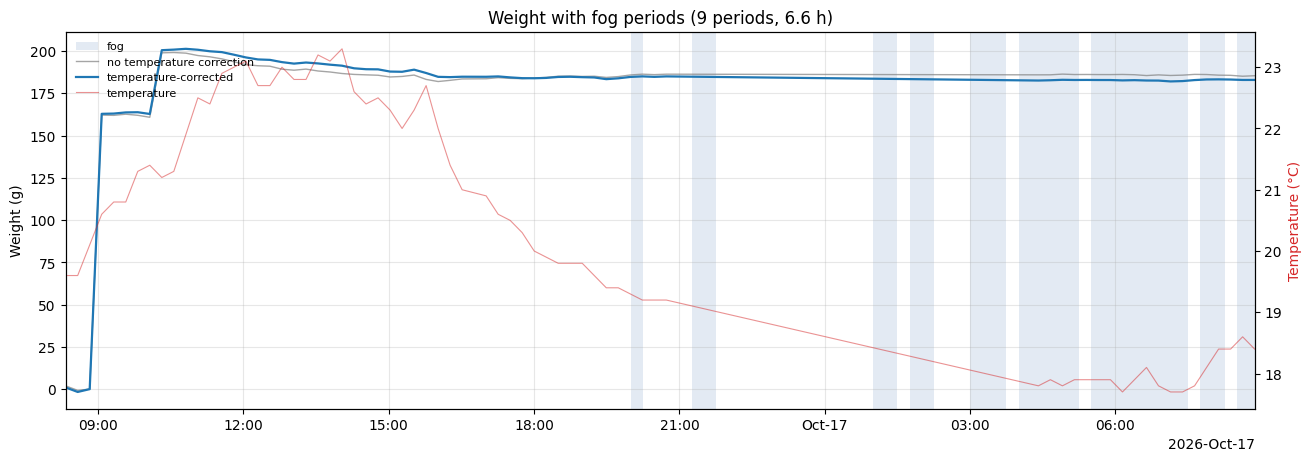

In [73]:
if not fog_periods:
    print("⏭ Skipped 'weight with fog flag': no fog periods in the window")
elif enough(dw["weight_g"].notna().sum(), "weight with fog flag"):
    fig, ax = plt.subplots(figsize=(13, 4.5), constrained_layout=True)
    shade(ax, fog_periods)
    ax.plot(dw["timestamp"], dw["weight_raw_g"], color="tab:grey", lw=1, alpha=0.7, label="no temperature correction")
    ax.plot(dw["timestamp"], dw["weight_g"], color="tab:blue", lw=1.6, label="temperature-corrected")
    ax.set_ylabel("Weight (g)")
    ax.set_xlim(t0, t1)
    tw = add_temperature(ax, dw)
    legend_all(ax, [ax, tw], loc="upper left")
    ax.set_title(f"Weight with fog periods ({len(fog_periods)} periods, {fog_hours:.1f} h)")
    time_axis(ax)
    finish(fig, "weight_fog_flag")

## 4. Weight with FIESTA fog interception
Expected water on the plant per interval = FIESTA fog (mm) × `PLANT_AREA_CM2` × 0.1 × `EFFICIENCY` (1 mm over 1 cm² = 0.1 g).

FIESTA fog in window: 0.000 mm → expected on plant 0.00 g (area 150 cm², efficiency 1)


,start,end,hours,fog_mm,expected_g,measured_change_g,measured / expected
0,2026-10-16 20:00:00,2026-10-16 20:15:00,0.25,0.0,0.0,0.33,NaN
1,2026-10-16 21:15:00,2026-10-16 21:45:00,0.50,0.0,0.0,0.00,NaN
2,2026-10-17 01:00:00,2026-10-17 01:30:00,0.50,0.0,0.0,0.00,NaN
3,2026-10-17 01:45:00,2026-10-17 02:15:00,0.50,0.0,0.0,0.00,NaN
4,2026-10-17 03:00:00,2026-10-17 03:45:00,0.75,0.0,0.0,0.00,NaN
5,2026-10-17 04:00:00,2026-10-17 05:15:00,1.25,0.0,0.0,0.33,NaN
6,2026-10-17 05:30:00,2026-10-17 07:30:00,2.00,0.0,0.0,-0.68,NaN
7,2026-10-17 07:45:00,2026-10-17 08:15:00,0.50,0.0,0.0,0.42,NaN
8,2026-10-17 08:30:00,2026-10-17 08:52:18,0.37,0.0,0.0,0.01,NaN


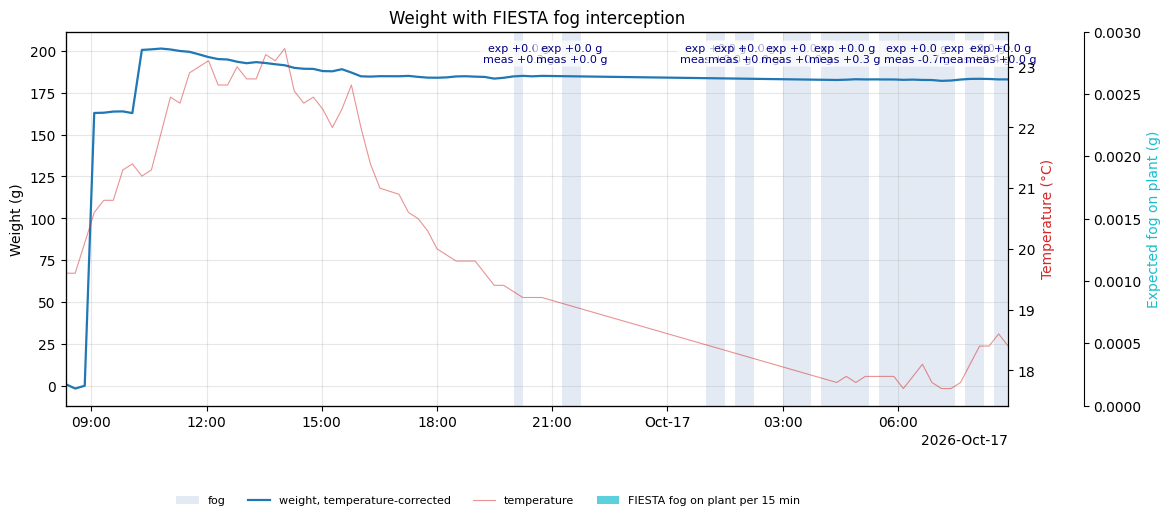

In [74]:
G_PER_MM = PLANT_AREA_CM2 * 0.1 * EFFICIENCY
if mw is None:
    print("⏭ Skipped 'FIESTA fog interception': no weather-station file")
elif FIESTA_COL not in mw.columns:
    print(f"⏭ Skipped 'FIESTA fog interception': no column '{FIESTA_COL}' in {MET_PATH}")
elif enough(len(mw), "FIESTA fog interception") and enough(dw["weight_g"].notna().sum(), "FIESTA fog interception"):
    mw["fog_expected_g"] = mw[FIESTA_COL] * G_PER_MM
    show_rain = bool(RAIN_COL) and RAIN_COL in mw.columns and mw[RAIN_COL].sum() > 0
    print(f"FIESTA fog in window: {mw[FIESTA_COL].sum():.3f} mm → expected on plant "
          f"{mw['fog_expected_g'].sum():.2f} g (area {PLANT_AREA_CM2:g} cm², efficiency {EFFICIENCY:g})"
          + (f" | rain {mw[RAIN_COL].sum():.1f} mm" if show_rain else ""))

    # Per fog period: expected interception vs measured weight change
    def w_at(t):
        return dw.loc[(dw["timestamp"] - t).abs().idxmin(), "weight_g"]
    rows = []
    for p, q in fog_periods:
        sel = (mw["Timestamp"] >= p) & (mw["Timestamp"] < q)
        exp_g, meas_g = mw.loc[sel, "fog_expected_g"].sum(), w_at(q) - w_at(p)
        r = {"start": p, "end": q, "hours": (q - p).total_seconds() / 3600, "fog_mm": mw.loc[sel, FIESTA_COL].sum(),
             "expected_g": exp_g, "measured_change_g": meas_g,
             "measured / expected": meas_g / exp_g if exp_g > 0 else np.nan}
        if show_rain:
            r["rain_mm"] = mw.loc[sel, RAIN_COL].sum()
        rows.append(r)
    fog_table = pd.DataFrame(rows)
    if len(fog_table):
        display(fog_table.round({k: 2 for k in fog_table.select_dtypes("number")}))

    fig, ax = plt.subplots(figsize=(13, 5.5))
    shade(ax, fog_periods)
    ax.plot(dw["timestamp"], dw["weight_g"], color="tab:blue", lw=1.6, label="weight, temperature-corrected")
    ax.set_ylabel("Weight (g)")
    ax.set_xlim(t0, t1)
    ax.set_zorder(3); ax.patch.set_visible(False)
    tw = add_temperature(ax, dw)

    bar_w = met_step / pd.Timedelta(days=1) * 0.9
    ax3 = ax.twinx(); ax3.grid(False)
    ax3.spines["right"].set_position(("axes", 1.08))
    ax3.bar(mw["Timestamp"], mw["fog_expected_g"], width=bar_w, align="edge", color="tab:cyan", alpha=0.7,
            label=f"FIESTA fog on plant per {int(met_step.total_seconds() // 60)} min")
    ax3.set_ylim(0, max(1e-3, mw["fog_expected_g"].max()) * 3)
    ax3.set_ylabel("Expected fog on plant (g)", color="tab:cyan")
    axes_ = [ax, tw, ax3]
    if show_rain:
        ax4 = ax.twinx(); ax4.grid(False)
        ax4.spines["right"].set_position(("axes", 1.18))
        ax4.bar(mw["Timestamp"], mw[RAIN_COL], width=bar_w, align="edge", color="tab:purple", alpha=0.5,
                label="rain")
        ax4.set_ylim(max(0.5, mw[RAIN_COL].max()) * 3, 0)
        ax4.set_ylabel("Rain (mm)", color="tab:purple")
        axes_.append(ax4)
    for _, r in fog_table.iterrows():
        ax.text(r["start"] + (r["end"] - r["start"]) / 2, 0.97,
                f"exp +{r['expected_g']:.1f} g\nmeas {r['measured_change_g']:+.1f} g",
                transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=8, color="navy",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.7))
    legend_all(fig, axes_, loc="lower center", ncol=4, bbox_to_anchor=(0.45, 0.0))
    ax.set_title("Weight with FIESTA fog interception")
    time_axis(ax)
    fig.subplots_adjust(right=0.78 if show_rain else 0.85, bottom=0.2)
    finish(fig, "weight_fiesta")

## 5. Evapotranspiration (water balance)
- **Watering check** (if `PRE_START`/`PRE_END` are set): measured weight gain vs. water added − drainage.
- **ET** over the drying period: ET = weight loss − drainage. Negative ET means water was gained (fog, dew, rain).

⏭ Skipped 'watering check (base period)': only 0 data point(s), need at least 1


,value
ET period length (h),24.54
ET (ml),-421.85
ET ± (ml),9.61
ET rate (ml/day),-412.58
drainage in ET period (ml),238.64
scale noise σ (g),0.58
ET (mm),-28.12
ET rate (mm/day),-27.51


ET per date and day part (ml; negative = water gained):


part,day,night,total
timestamp,,,
2026-10-16,-421.6,-1.0,-422.6
2026-10-17,-0.1,2.1,2.1


ET during fog +2.3 ml | outside fog -422.8 ml
⚠ Sudden weight jumps at 10-16 09:04, 10-16 10:19: disturbance?


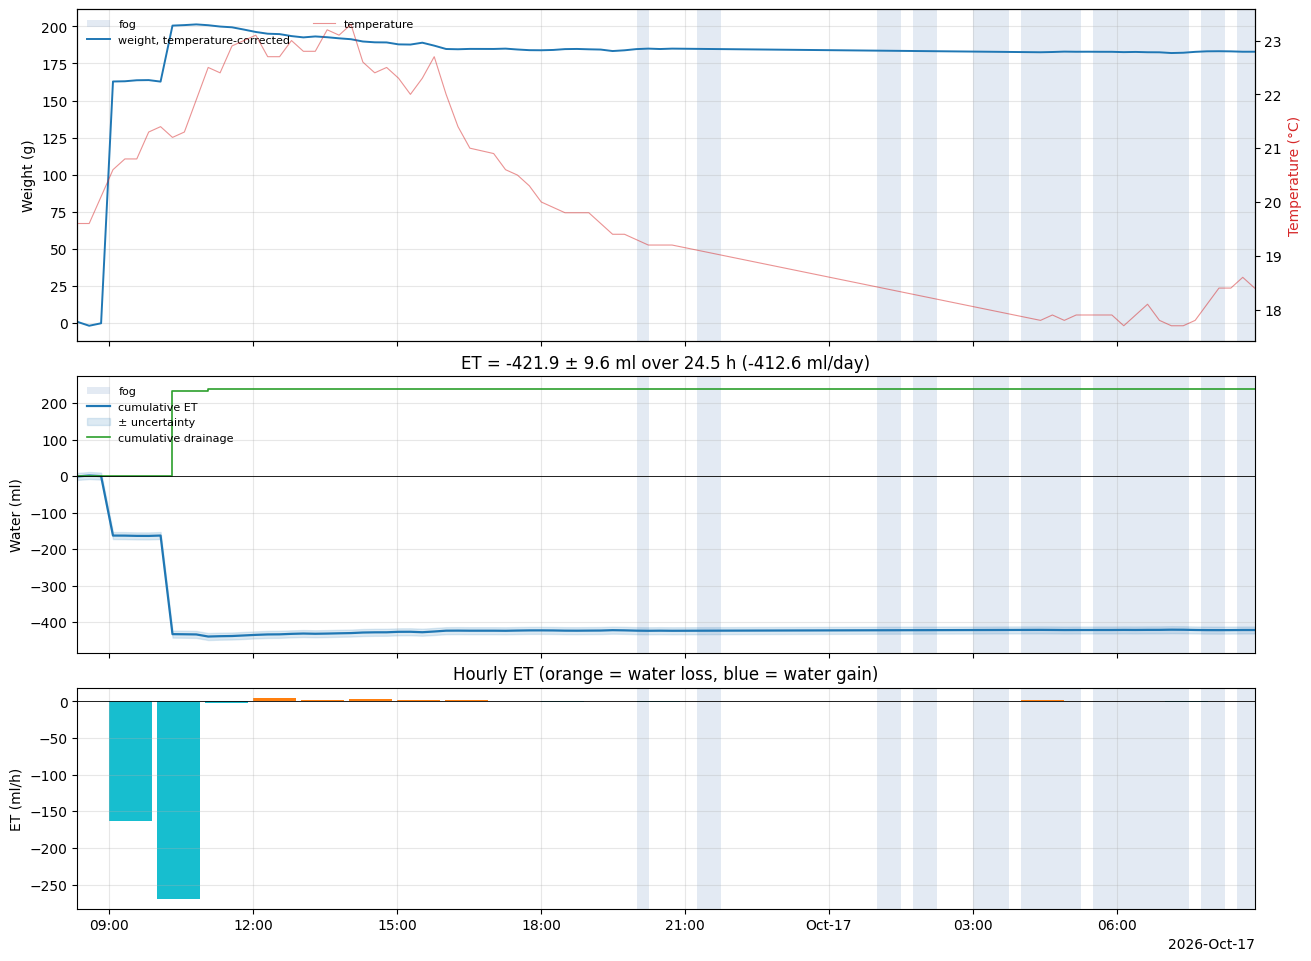

In [75]:
et = select_window(dw, ET_START, ET_END)
if enough(et["weight_g"].notna().sum(), "evapotranspiration"):
    # Scale noise from quiet steps (no tips, no large jumps)
    d = dw["weight_g"].diff()[dw["tips_inc"] == 0]
    sigma_w = d[d.abs() < 5 * d.abs().median() + 1].std() / np.sqrt(2)
    sigma_end = sigma_w / np.sqrt(N_AVG)
    n = min(N_AVG, len(et))

    res = {}
    pre = None
    # ---- Watering check ----
    if PRE_START is not None and PRE_END is not None:
        pre = select_window(dw, PRE_START, PRE_END)
        if enough(len(pre), "watering check (base period)", need=1):
            wat = dw[(dw["timestamp"] > pre["timestamp"].iloc[-1]) & (dw["timestamp"] < et["timestamp"].iloc[0])]
            W_base, W_after = pre["weight_g"].mean(), et["weight_g"].iloc[:n].mean()
            gain, D_water = W_after - W_base, wat["tips_inc"].sum() * TIP_ML
            closure = gain - (WATER_ADDED_ML - D_water)
            sig_water = np.sqrt(2 * sigma_end**2 + TIP_ML**2 + (TIP_CAL_ERR * D_water)**2 + (TEMP_RESID * abs(
                et["avg_temperature_C"].iloc[:n].mean() - pre["avg_temperature_C"].mean()))**2)
            res.update({"base weight before watering (g)": W_base, "weight after drainage (g)": W_after,
                        "measured weight gain (g)": gain, "drainage during watering (ml)": D_water,
                        "expected retained = added − drained (ml)": WATER_ADDED_ML - D_water,
                        "watering closure error (g)": closure, "watering closure ± (g)": sig_water})
            if abs(closure) > 2 * sig_water:
                print(f"⚠ Watering doesn't close: gained {gain:.0f} g, expected {WATER_ADDED_ML - D_water:.0f} ml "
                      f"retained ({closure:+.0f} g). Water missed the plant, ran off, or tips were under-counted.")
        else:
            pre = None

    # ---- ET over the drying period ----
    et["drain_ml"] = et["tips_inc"].cumsum() * TIP_ML
    W0, W1 = et["weight_g"].iloc[:n].mean(), et["weight_g"].iloc[-n:].mean()
    T0, T1 = et["avg_temperature_C"].iloc[:n].mean(), et["avg_temperature_C"].iloc[-n:].mean()
    et["ET_ml"] = W0 - et["weight_g"] - et["drain_ml"]
    D_et = et["drain_ml"].iloc[-1]
    ET = (W0 - W1) - D_et
    h = (et["timestamp"].iloc[-1] - et["timestamp"].iloc[0]).total_seconds() / 3600
    sig_ET = np.sqrt(2 * sigma_end**2 + (TIP_ML if D_et > 0 else 0)**2 + (TIP_CAL_ERR * D_et)**2
                     + (TEMP_RESID * abs(T1 - T0))**2)
    res.update({"ET period length (h)": h, "ET (ml)": ET, "ET ± (ml)": sig_ET,
                "ET rate (ml/day)": 24 * ET / h if h else np.nan,
                "drainage in ET period (ml)": D_et, "scale noise σ (g)": sigma_w})
    if AREA_CM2:
        res["ET (mm)"] = ET / AREA_CM2 * 10
        res["ET rate (mm/day)"] = res["ET (mm)"] * 24 / h if h else np.nan
    display(pd.Series(res).round(2).to_frame("value"))

    # ---- Day / night and fog / no fog ----
    et["dET"] = et["ET_ml"].diff().fillna(0)
    et["part"] = np.where(et["timestamp"].dt.hour.between(DAY_HOURS[0], DAY_HOURS[1] - 1), "day", "night")
    split = et.pivot_table(index=et["timestamp"].dt.date, columns="part", values="dET", aggfunc="sum").fillna(0)
    split["total"] = split.sum(axis=1)
    print("ET per date and day part (ml; negative = water gained):")
    display(split.round(1))
    in_fog = np.zeros(len(et), bool)
    for p, q in fog_periods:
        in_fog |= ((et["timestamp"] >= p) & (et["timestamp"] < q)).values
    if in_fog.any():
        print(f"ET during fog {et['dET'][in_fog].sum():+.1f} ml | outside fog {et['dET'][~in_fog].sum():+.1f} ml")

    jumps = et.loc[et["weight_g"].diff().abs() > 10 * sigma_w + TIP_ML, "timestamp"]
    if len(jumps):
        print(f"⚠ Sudden weight jumps at {', '.join(t.strftime('%m-%d %H:%M') for t in jumps)}: disturbance?")

    # ---- ET rate per hour ----
    rate = et.set_index("timestamp")["dET"].resample("1h").sum(min_count=1)

    # ---- Plot ----
    fig, axs = plt.subplots(3, 1, figsize=(13, 9.5), sharex=True, constrained_layout=True,
                            gridspec_kw={"height_ratios": [1.2, 1, 0.8]})
    for a_ in axs:
        shade(a_, fog_periods)
    ax1 = axs[0]
    if pre is not None:
        ax1.axvspan(pre["timestamp"].iloc[0], pre["timestamp"].iloc[-1], color="tab:green", alpha=0.12,
                    label="base period")
        ax1.axvspan(pre["timestamp"].iloc[-1], et["timestamp"].iloc[0], color="tab:orange", alpha=0.12,
                    label="watering + drainage")
    ax1.plot(dw["timestamp"], dw["weight_g"], color="tab:blue", lw=1.4, label="weight, temperature-corrected")
    ax1.set_ylabel("Weight (g)")
    tw = add_temperature(ax1, dw)
    legend_all(ax1, [ax1, tw], loc="upper left", ncol=2)

    axs[1].plot(et["timestamp"], et["ET_ml"], color="tab:blue", lw=1.6, label="cumulative ET")
    axs[1].fill_between(et["timestamp"], et["ET_ml"] - sig_ET, et["ET_ml"] + sig_ET, color="tab:blue", alpha=0.15,
                        label="± uncertainty")
    if D_et > 0:
        axs[1].step(et["timestamp"], et["drain_ml"], where="post", color="tab:green", lw=1.2, label="cumulative drainage")
    axs[1].axhline(0, color="k", lw=0.6)
    axs[1].set_ylabel("Water (ml)")
    axs[1].set_title(f"ET = {ET:.1f} ± {sig_ET:.1f} ml over {h:.1f} h ({24 * ET / h:.1f} ml/day)")
    axs[1].legend(loc="upper left", fontsize=8, frameon=False)

    if enough(rate.notna().sum(), "hourly ET rate", need=3):
        axs[2].bar(rate.index, rate.values, width=1 / 24 * 0.9, align="edge",
                   color=np.where(rate.values >= 0, "tab:orange", "tab:cyan"))
        axs[2].axhline(0, color="k", lw=0.6)
        axs[2].set_ylabel("ET (ml/h)")
        axs[2].set_title("Hourly ET (orange = water loss, blue = water gain)")
    else:
        axs[2].set_visible(False)
    axs[0].set_xlim(dw["timestamp"].min(), dw["timestamp"].max())
    time_axis(axs[2])
    finish(fig, "evapotranspiration")

## 6. Manual weighings check (optional)

,timestamp,manual_g,logger_tc_g,logger_raw_g,diff_tc_g,diff_raw_g
0,2026-10-16 12:15:00,200,195.3,191.4,-4.7,-8.6
1,2026-10-16 14:25:00,200,189.5,186.0,-10.5,-14.0
2,2026-10-16 16:30:00,190,184.8,183.4,-5.2,-6.6
3,2026-10-16 19:50:00,175,184.2,185.3,9.2,10.3
4,2026-10-16 21:00:00,180,184.9,186.3,4.9,6.3
5,2026-10-17 07:00:00,200,182.3,185.7,-17.7,-14.3
6,2026-10-17 08:31:00,185,183.0,185.3,-2.0,0.3


Logger temperature-corrected : mean offset -3.7 g | scatter after removing offset (RMS) 8.4 g
Logger no correction         : mean offset -3.8 g | scatter after removing offset (RMS) 8.9 g


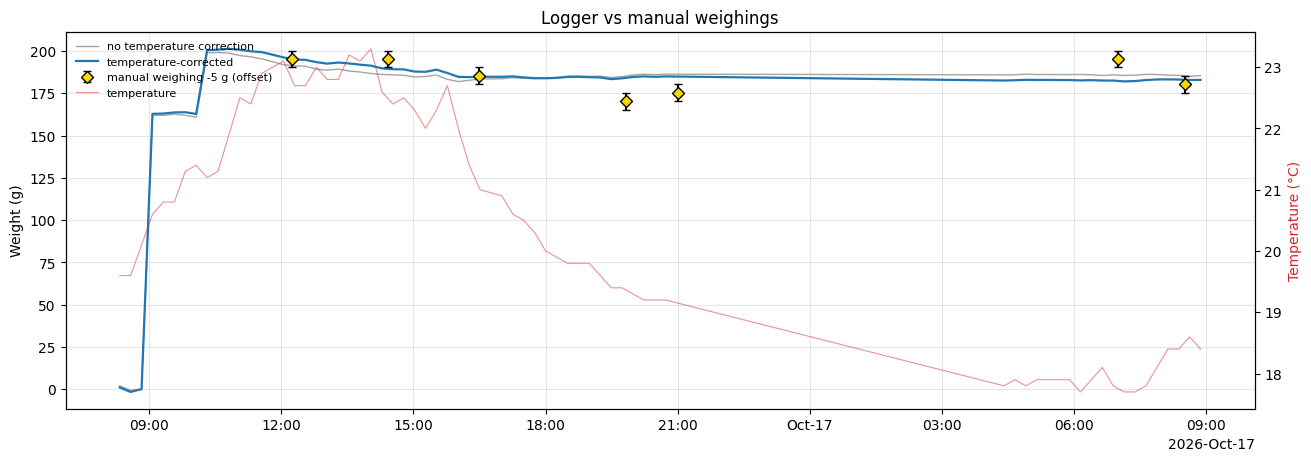

In [76]:
if not MANUAL:
    print("⏭ Skipped 'manual weighings': MANUAL is empty")
else:
    day = pd.Timestamp(MANUAL_START_DATE) if MANUAL_START_DATE else t0.normalize()
    times, prev = [], None
    for hhmm, _ in MANUAL:
        hh, mm = map(int, hhmm.split(":"))
        t = day + pd.Timedelta(hours=hh, minutes=mm)
        if prev is not None and t <= prev:       # clock went back -> next day
            day += pd.Timedelta(days=1); t += pd.Timedelta(days=1)
        times.append(t); prev = t
    man = pd.DataFrame({"timestamp": times, "manual_g": [w for _, w in MANUAL]})
    x, xm = dw["timestamp"].astype("int64").values, man["timestamp"].astype("int64").values
    inside = (xm >= x.min()) & (xm <= x.max())
    for col, out in (("weight_g", "logger_tc_g"), ("weight_raw_g", "logger_raw_g")):
        man[out] = np.where(inside, np.interp(xm, x, dw[col].values), np.nan)
    man["diff_tc_g"], man["diff_raw_g"] = man["logger_tc_g"] - man["manual_g"], man["logger_raw_g"] - man["manual_g"]
    display(man.round({k: 1 for k in man.select_dtypes("number")}))
    m = man.dropna(subset=["diff_tc_g"])
    if enough(len(m), "manual weighings", need=2):
        for col, name in (("tc", "temperature-corrected"), ("raw", "no correction")):
            dd = m[f"diff_{col}_g"]
            print(f"Logger {name:22s}: mean offset {dd.mean():+.1f} g | scatter after removing offset "
                  f"(RMS) {np.sqrt(((dd - dd.mean())**2).mean()):.1f} g")
        off = m["diff_tc_g"].median()
        fig, ax = plt.subplots(figsize=(13, 4.5), constrained_layout=True)
        ax.plot(dw["timestamp"], dw["weight_raw_g"], color="tab:grey", lw=1, alpha=0.7, label="no temperature correction")
        ax.plot(dw["timestamp"], dw["weight_g"], color="tab:blue", lw=1.6, label="temperature-corrected")
        ax.errorbar(m["timestamp"], m["manual_g"] + off, yerr=MANUAL_RES_G, fmt="D", ms=6, color="black",
                    mfc="gold", capsize=3, zorder=5, label=f"manual weighing {off:+.0f} g (offset)")
        ax.set_ylabel("Weight (g)")
        tw = add_temperature(ax, dw)
        legend_all(ax, [ax, tw], loc="upper left")
        ax.set_title("Logger vs manual weighings")
        time_axis(ax)
        finish(fig, "manual_weighings")

## 7. Report summary: pass criteria
Minimal numbers and figures for the report. The watering times come from `PRE_START`, `PRE_END` and `ET_START`
in the settings; if those don't fall inside the data, they are detected automatically (the weight step just before
the first drainage burst) and printed, so check them.

- **Enclosure integrity**: logging continuity (readings, gaps, resets, faults) and humidity. Condensation on opening is a
  visual check: set `CONDENSATION_SEEN`.
- **Water balance closure**: ΔS (weight after drainage stopped − weight before watering) + D (drainage) vs water applied.
- **Tracking accuracy**: logger vs manual weighings during drying, after removing the constant offset (tare).
  Readings where the plant was lifted off the lysimeter (e.g. for a manual weighing) are excluded.

In [77]:
# ---------------- phases: base, watering + drainage, drying ----------------
w = dw.dropna(subset=["weight_g"]).reset_index(drop=True)
step = w["timestamp"].diff().median()
sig_w = 1.4826 * (w["weight_g"].diff().diff() - w["weight_g"].diff().diff().median()).abs().median() / np.sqrt(6)

# disturbed readings: single readings far below their neighbours (plant lifted off the lysimeter)
med = w["weight_g"].rolling(5, center=True, min_periods=3).median()
w["disturbed"] = (med - w["weight_g"]) > max(20, 10 * sig_w)     # dips only: watering peaks are real

def _inside(t):
    return t is not None and w["timestamp"].min() <= pd.Timestamp(t) <= w["timestamp"].max()

if _inside(PRE_START) and _inside(PRE_END) and _inside(ET_START):
    pre_a, pre_b, post_a = pd.Timestamp(PRE_START), pd.Timestamp(PRE_END), pd.Timestamp(ET_START)
    how = "from the settings"
else:
    first_tip = w.loc[w["tips_inc"] > 0, "timestamp"].min()
    if pd.isna(first_tip):
        raise ValueError("No drainage in the data: set PRE_START, PRE_END and ET_START for the watering")
    # watering = the largest weight rise in the hour before the first tip
    cand = w[(w["timestamp"] <= first_tip) & (w["timestamp"] >= first_tip - pd.Timedelta("1h")) & ~w["disturbed"]]
    k = cand["weight_g"].diff().idxmax() if len(cand) > 1 else w.index[w["timestamp"] == first_tip][0]
    pre_b = w.loc[k - 1, "timestamp"]
    pre_a = pre_b - pd.Timedelta("1h")
    # drainage burst: tips no more than 1 h apart; drying starts one interval after the last tip of the burst
    tip_t = w.loc[(w["tips_inc"] > 0) & (w["timestamp"] >= first_tip), "timestamp"]
    last = tip_t.iloc[0]
    for t_ in tip_t.iloc[1:]:
        if t_ - last > pd.Timedelta("1h"):
            break
        last = t_
    post_a = last + step
    how = "detected automatically"
pre = w[(w["timestamp"] >= pre_a) & (w["timestamp"] <= pre_b) & ~w["disturbed"]]
post = w[(w["timestamp"] >= post_a) & ~w["disturbed"]]
print(f"Phases ({how}): base {pre_a:%m-%d %H:%M}–{pre_b:%H:%M} ({len(pre)} readings), "
      f"watering + drainage {pre_b:%H:%M}–{post_a:%H:%M}, drying from {post_a:%m-%d %H:%M} ({len(post)} readings)")

# ---------------- 1. enclosure integrity ----------------
gaps = w["timestamp"].diff()
n_exp = int(round((w["timestamp"].iloc[-1] - w["timestamp"].iloc[0]) / step)) + 1
normal = df["status"].mode().iloc[0]
faults = df[df["status"].str.contains("HX_|ERR|FAIL", case=False, regex=True)]
other = df[(df["status"] != normal) & ~df["status"].str.contains("BOOT", case=False) & ~df.index.isin(faults.index)]
resets = dw["boot_session"].nunique() - 1 + int((dw["elapsed_sec"].diff() < 0).sum())
rh = w["avg_humidity_pct"]
dur_h = gaps.shift(-1).fillna(step).clip(upper=step) / pd.Timedelta("1h")       # time each reading stands for
sat_h = float((dur_h * (rh >= RH_SATURATED)).sum())
big_gaps = w.loc[gaps > 1.5 * step, "timestamp"]
integ = {
    "logging period": f"{w['timestamp'].iloc[0]:%Y-%m-%d %H:%M} → {w['timestamp'].iloc[-1]:%Y-%m-%d %H:%M} "
                      f"({(w['timestamp'].iloc[-1] - w['timestamp'].iloc[0]) / pd.Timedelta('1h'):.1f} h)",
    "readings logged / expected": f"{len(w)} / {n_exp} ({len(w) / n_exp:.0%}) at {int(step.total_seconds() // 60)} min",
    "longest gap": f"{gaps.max()}" + (f" (ends {big_gaps.iloc[gaps[gaps > 1.5 * step].values.argmax()]:%m-%d %H:%M})" if len(big_gaps) else ""),
    "resets (reboots)": resets,
    "load-cell faults (HX_)": len(faults),
    "other status flags": ", ".join(f"{k} ×{v}" for k, v in other["status"].value_counts().items()) or "none",
    "disturbed readings (plant lifted)": ", ".join(w.loc[w["disturbed"], "timestamp"].dt.strftime("%m-%d %H:%M")) or "none",
    "RH max / time ≥ " + f"{RH_SATURATED} %": f"{rh.max():.1f} % / {sat_h:.1f} h",
    "condensation on opening": {True: "yes", False: "none seen", None: "not recorded"}[CONDENSATION_SEEN],
}
logging_ok = resets == 0 and len(faults) == 0 and not len(big_gaps)
integ_ok = logging_ok and CONDENSATION_SEEN is False

# ---------------- 2. water balance closure ----------------
n_ = min(N_AVG, len(post))
W_pre, W_post = pre["weight_g"].mean(), post["weight_g"].iloc[:n_].mean()
dS = W_post - W_pre
D = w.loc[(w["timestamp"] > pre_b) & (w["timestamp"] <= post_a), "tips_inc"].sum() * TIP_ML
tot = dS + D
err = tot - WATER_ADDED_ML
dT_ = abs(post["avg_temperature_C"].iloc[:n_].mean() - pre["avg_temperature_C"].mean())
sd = np.sqrt(sig_w**2 / len(pre) + sig_w**2 / n_ + (TIP_ML / 2)**2 + (TIP_CAL_ERR * D)**2 + (TEMP_RESID * dT_)**2)
closure_ok = abs(err) <= CLOSURE_TOL * WATER_ADDED_ML
clos = {
    "water applied (g)": WATER_ADDED_ML,
    "storage change ΔS (g)": dS,
    f"drainage D (g) [{int(D / TIP_ML)} tips × {TIP_ML} ml]": D,
    "ΔS + D (g)": tot,
    "difference (g)": err,
    "difference (%)": 100 * err / WATER_ADDED_ML,
    "uncertainty ± (g)": sd,
}

# ---------------- 3. tracking accuracy vs manual weighings ----------------
day = pd.Timestamp(MANUAL_START_DATE) if MANUAL_START_DATE else t0.normalize()
times, prev_ = [], None
for hhmm, _ in MANUAL:
    hh, mm = map(int, hhmm.split(":"))
    t_ = day + pd.Timedelta(hours=hh, minutes=mm)
    if prev_ is not None and t_ <= prev_:
        day += pd.Timedelta(days=1); t_ += pd.Timedelta(days=1)
    times.append(t_); prev_ = t_
mt = pd.DataFrame({"timestamp": times, "manual_g": [v for _, v in MANUAL]})
ok_w = w[~w["disturbed"]]
x = ok_w["timestamp"].astype("int64").to_numpy()
xm = mt["timestamp"].astype("int64").to_numpy()
near = np.array([np.abs(x - v).min() <= 1.5 * step.value for v in xm]) if len(x) else np.zeros(len(mt), bool)
mt["logger_g"] = np.where(near & (xm >= x.min()) & (xm <= x.max()), np.interp(xm, x, ok_w["weight_g"]), np.nan)
mt["in drying phase"] = mt["timestamp"] >= post_a
m = mt[mt["in drying phase"] & mt["logger_g"].notna()].copy()
if len(m):
    offset = (m["logger_g"] - m["manual_g"]).median()
    m["residual_g"] = m["logger_g"] - offset - m["manual_g"]
    mt.loc[m.index, "residual_g"] = m["residual_g"]
    max_abs = m["residual_g"].abs().max()
    track = {"manual weighings compared": f"{len(m)} of {len(mt)} (others outside the log or before drying)",
             "offset logger − manual (g)": offset,
             "mean residual (g)": m["residual_g"].mean(),
             "RMS residual (g)": np.sqrt((m["residual_g"]**2).mean()),
             "max |residual| (g)": max_abs,
             "manual scale resolution (g)": f"± {MANUAL_RES_G}"}
    track_ok = None if TRACK_TOL_G is None else max_abs <= TRACK_TOL_G
else:
    track, track_ok, max_abs = {"manual weighings compared": "none in the drying phase"}, None, np.nan

# ---------------- drying phase: mass loss and humidity ----------------
dp = post.copy()
dp["dW"] = dp["weight_g"].diff()
dp["dt_h"] = dp["timestamp"].diff() / pd.Timedelta("1h")
dp = dp[dp["dt_h"] <= 1.5 * step / pd.Timedelta("1h")]
dp["dD"] = dp["tips_inc"] * TIP_ML
dp["RH class"] = pd.cut(dp["avg_humidity_pct"], [0, 90, RH_SATURATED, 101],
                        labels=["RH < 90 %", f"RH 90–{RH_SATURATED} %", f"RH ≥ {RH_SATURATED} %"], right=False)
dry_tab = dp.groupby("RH class", observed=True).agg(hours=("dt_h", "sum"), loss_g=("dW", lambda s: -s.sum()),
                                                  drain_g=("dD", "sum"))
dry_tab["ET (g)"] = dry_tab["loss_g"] - dry_tab["drain_g"]
dry_tab["ET rate (g/h)"] = dry_tab["ET (g)"] / dry_tab["hours"]
if AREA_CM2:
    dry_tab["ET rate (mm/h)"] = dry_tab["ET rate (g/h)"] * 10 / AREA_CM2
dry_tab = dry_tab.drop(columns=["loss_g", "drain_g"])

# ---------------- tables ----------------
verdict = lambda ok: "—" if ok is None else ("PASS" if ok else "FAIL")
fmt = lambda v: f"{v:.1f}" if isinstance(v, (float, np.floating)) else str(v)
summary = pd.DataFrame([
    ["Enclosure integrity", "logging continuous: no resets, faults or gaps",
     f"{integ['resets (reboots)']} resets, {integ['load-cell faults (HX_)']} faults, longest gap {gaps.max()}", verdict(logging_ok)],
    ["", "no condensation on opening", integ["condensation on opening"] + f" (RH ≥ {RH_SATURATED} % for {sat_h:.1f} h)",
     verdict(None if CONDENSATION_SEEN is None else not CONDENSATION_SEEN)],
    ["Water balance closure", f"ΔS + D within ±{CLOSURE_TOL:.0%} of {WATER_ADDED_ML} g",
     f"{tot:.1f} g ({100 * err / WATER_ADDED_ML:+.1f} %, ± {sd:.1f} g)", verdict(closure_ok)],
    ["Tracking accuracy", f"|logger − manual| ≤ ±{'X' if TRACK_TOL_G is None else TRACK_TOL_G} g during drying",
     f"max {max_abs:.1f} g, RMS {track.get('RMS residual (g)', np.nan):.1f} g (n = {len(m)})", verdict(track_ok)],
], columns=["criterion", "target", "result", "verdict"])
display(summary.style.hide(axis="index"))
print("Details")
for name, d_ in (("Enclosure integrity", integ), ("Water balance closure", clos), ("Tracking accuracy", track)):
    display(pd.Series({k: fmt(v) for k, v in d_.items()}, name=name).to_frame())
print("Drying phase: ET by humidity (evaporation stops when the air is saturated)")
display(dry_tab.round(2))

Phases (detected automatically): base 10-16 09:04–10:04 (5 readings), watering + drainage 10:04–11:18, drying from 10-16 11:18 (57 readings)


criterion,target,result,verdict
Enclosure integrity,"logging continuous: no resets, faults or gaps","0 resets, 0 faults, longest gap 0 days 07:40:45",FAIL
,no condensation on opening,not recorded (RH ≥ 99 % for 7.9 h),—
Water balance closure,ΔS + D within ±5% of 300 g,"274.4 g (-8.5 %, ± 8.0 g)",FAIL
Tracking accuracy,|logger − manual| ≤ ±X g during drying,"max 13.9 g, RMS 8.4 g (n = 7)",—


Details


,Enclosure integrity
logging period,2026-10-16 08:19 → 2026-10-17 08:52 (24.5 h)
readings logged / expected,69 / 100 (69%) at 14 min
longest gap,0 days 07:40:45 (ends 10-17 04:24)
resets (reboots),0
load-cell faults (HX_),0
other status flags,none
disturbed readings (plant lifted),none
RH max / time ≥ 99 %,100.0 % / 7.9 h
condensation on opening,not recorded


,Water balance closure
water applied (g),300
storage change ΔS (g),35.8
drainage D (g) [38 tips × 6.28 ml],238.6
ΔS + D (g),274.4
difference (g),-25.6
difference (%),-8.5
uncertainty ± (g),8.0


,Tracking accuracy
manual weighings compared,7 of 7 (others outside the log or before drying)
offset logger − manual (g),-4.7
mean residual (g),1.0
RMS residual (g),8.4
max |residual| (g),13.9
manual scale resolution (g),± 5


Drying phase: ET by humidity (evaporation stops when the air is saturated)


,hours,ET (g),ET rate (g/h),ET rate (mm/h)
RH class,,,,
RH < 90 %,4.71,15.12,3.21,0.21
RH 90–99 %,1.74,0.60,0.35,0.02
RH ≥ 99 %,6.94,-1.25,-0.18,-0.01


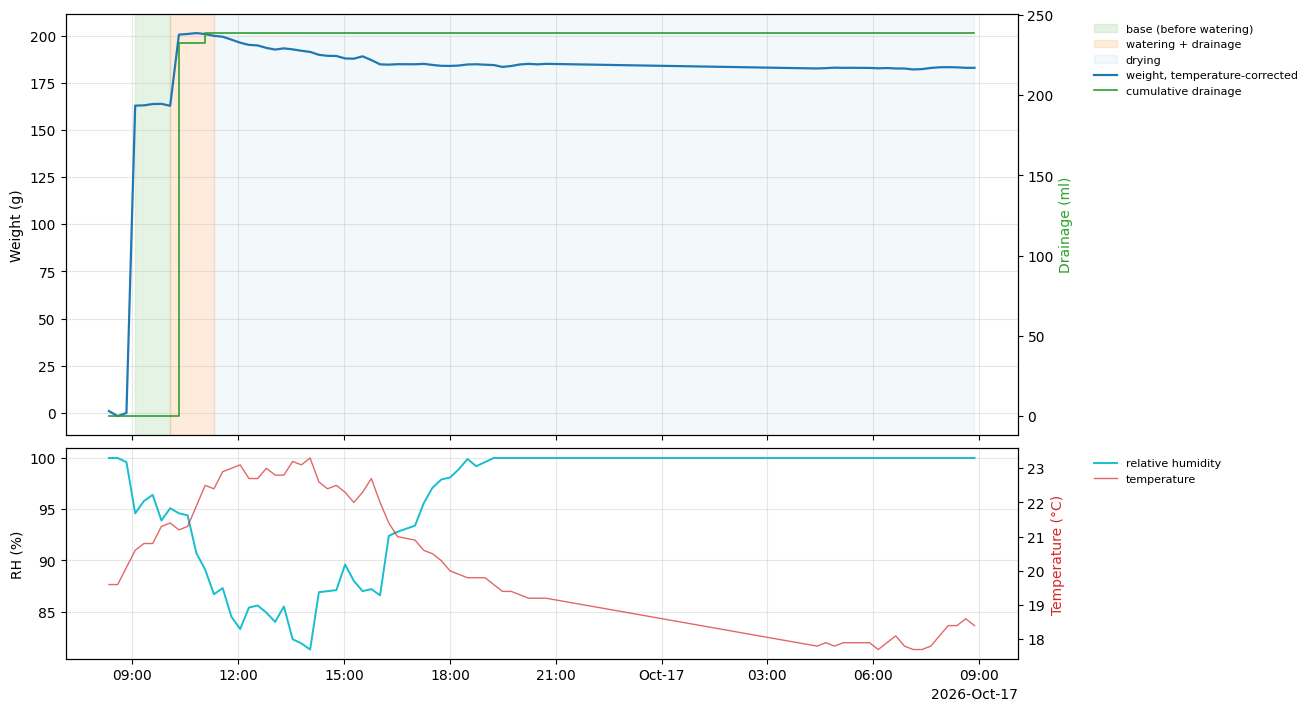

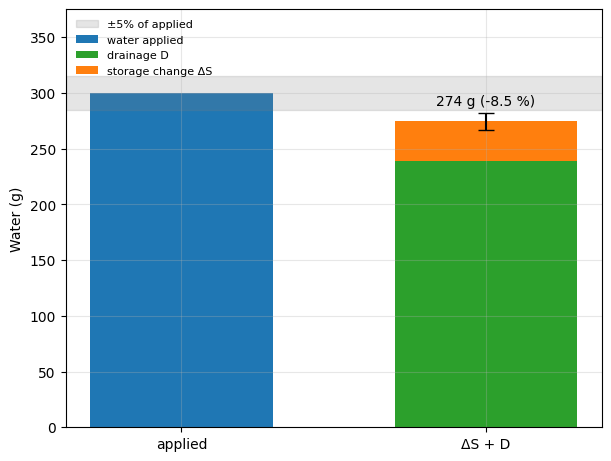

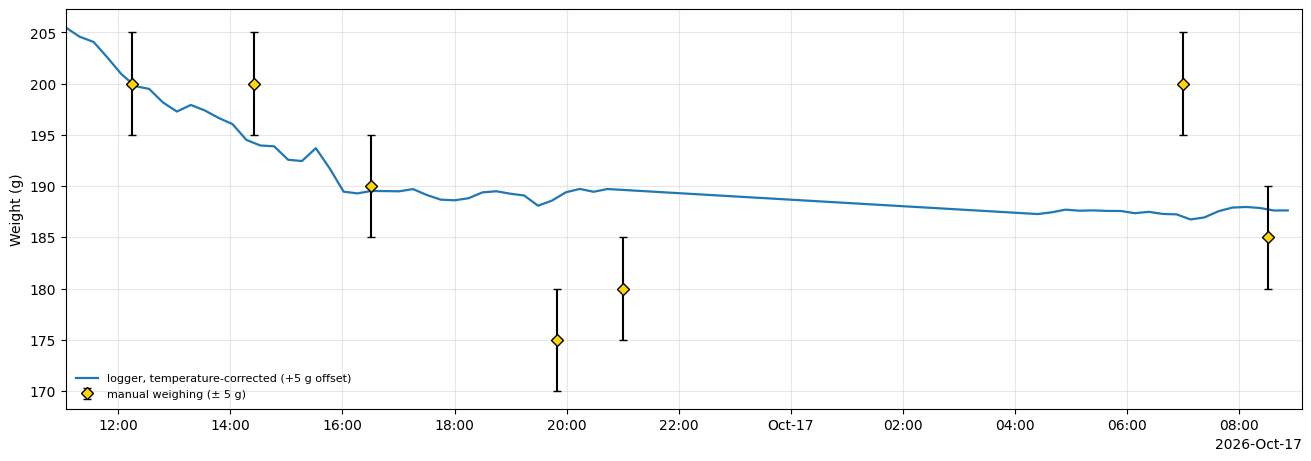

In [80]:
# ---------------- Figure 1: experiment overview with humidity ----------------
fig, (ax, axh) = plt.subplots(2, 1, figsize=(13, 7), sharex=True, constrained_layout=True,
                              gridspec_kw={"height_ratios": [2, 1]})
ax.axvspan(pre_a, pre_b, color="tab:green", alpha=0.12, label="base (before watering)")
ax.axvspan(pre_b, post_a, color="tab:orange", alpha=0.15, label="watering + drainage")
ax.axvspan(post_a, w["timestamp"].iloc[-1], color="tab:blue", alpha=0.05, label="drying")

ok_ = ~w["disturbed"]
ax.plot(w.loc[ok_, "timestamp"], w.loc[ok_, "weight_g"], color="tab:blue", lw=1.6, label="weight, temperature-corrected")
if w["disturbed"].any():
    ax.scatter(w.loc[~ok_, "timestamp"], w.loc[~ok_, "weight_g"], marker="x", color="red", zorder=5,
               label="plant lifted off (excluded)")
ax.set_ylabel("Weight (g)")
td = ax.twinx(); td.grid(False)
td.step(w["timestamp"], w["drain_ml"], where="post", color="tab:green", lw=1.2, label="cumulative drainage")
td.set_ylabel("Drainage (ml)", color="tab:green")
legend_all(ax, [ax, td], loc="upper left", bbox_to_anchor=(1.07, 1))
axh.plot(w["timestamp"], w["avg_humidity_pct"], color="tab:cyan", lw=1.4, label="relative humidity")
axh.set_ylabel("RH (%)")
tt = axh.twinx(); tt.grid(False)
tt.plot(w["timestamp"], w["avg_temperature_C"], color="tab:red", lw=1, alpha=0.7, label="temperature")
tt.set_ylabel("Temperature (°C)", color="tab:red")
legend_all(axh, [axh, tt], loc="upper left", bbox_to_anchor=(1.07, 1))
time_axis(axh)
finish(fig, "report_overview")

# ---------------- Figure 2: water balance closure ----------------
fig, ax = plt.subplots(figsize=(6, 4.5), constrained_layout=True)
ax.bar(0, WATER_ADDED_ML, color="tab:blue", width=0.6, label="water applied")
ax.bar(1, D, color="tab:green", width=0.6, label="drainage D")
ax.bar(1, dS, bottom=D, color="tab:orange", width=0.6, yerr=sd, capsize=6, label="storage change ΔS")
ax.axhspan(WATER_ADDED_ML * (1 - CLOSURE_TOL), WATER_ADDED_ML * (1 + CLOSURE_TOL), color="grey", alpha=0.2,
           label=f"±{CLOSURE_TOL:.0%} of applied")
ax.text(1, tot + sd + 4, f"{tot:.0f} g ({100 * err / WATER_ADDED_ML:+.1f} %)", ha="center", va="bottom")
ax.set_xticks([0, 1], ["applied", "ΔS + D"])
ax.set_ylabel("Water (g)")
ax.set_ylim(0, max(WATER_ADDED_ML, tot) * 1.25)
ax.legend(fontsize=8, frameon=False, loc="upper left")
finish(fig, "report_closure")

# ---------------- Figure 3: tracking vs manual weighings ----------------
if len(m):
    fig, ax = plt.subplots(figsize=(13, 4.5), constrained_layout=True)
    dd = w[(w["timestamp"] >= post_a - step) & ~w["disturbed"]]
    ax.plot(dd["timestamp"], dd["weight_g"] - offset, color="tab:blue", lw=1.6,
            label=f"logger, temperature-corrected ({-offset:+.0f} g offset)")
    ax.errorbar(m["timestamp"], m["manual_g"], yerr=MANUAL_RES_G, fmt="D", ms=6, color="black", mfc="gold",
                capsize=3, zorder=5, label=f"manual weighing (± {MANUAL_RES_G} g)")
    rest = mt[~mt.index.isin(m.index)]
    if len(rest):
        ax.scatter(rest["timestamp"], rest["manual_g"], marker="D", s=30, facecolor="none", edgecolor="grey",
                   label="manual, not compared (outside log / before drying)")
    ax.set_ylabel("Weight (g)")
    ax.legend(fontsize=8, frameon=False, loc="lower left")
    ax.set_xlim(post_a - step, max(w["timestamp"].iloc[-1], mt["timestamp"].max()) + step)
    time_axis(ax)
    finish(fig, "report_tracking")